# Factors Discouraging Students from Using AI for Homework
**Shiyao Liang (slian088) | CS105 Fall 2026**

This analysis compares six reported deterrents to AI use and tests whether learning-related concerns receive higher ratings than distrust of AI and difficulty using it.


## Research question and hypothesis
**Research question:** What factors discourage students from using AI when completing homework assignments?

**Hypothesis:** The average of the two learning-related ratings (wanting to learn independently and needing to work without AI later) is higher than the average of the distrust and AI-use-skill ratings.


## Data source

The repository workbook contains 86 survey responses and 175 columns. This analysis uses six homework deterrent questions from columns DE–DJ of `data/uncleaned_data.xlsx` (sheet `Form Responses 1`).


In [1]:
from pathlib import Path
import hashlib
import pandas as pd

# Locate the repository whether launched from this folder or the repository root.
repo_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'data' / "uncleaned_data.xlsx").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Could not locate data/uncleaned_data.xlsx in the repository.')
source_path = repo_root / 'data' / "uncleaned_data.xlsx"
output_dir = repo_root / 'working_folders' / 'slian088'
data = pd.read_excel(source_path, sheet_name='Form Responses 1')
print(f'Source: {source_path.relative_to(repo_root)}')
print(f'Responses: {len(data)}; columns: {data.shape[1]}')
print('Workbook SHA-256:', hashlib.sha256(source_path.read_bytes()).hexdigest())


Source: data/uncleaned_data.xlsx
Responses: 86; columns: 175
Workbook SHA-256: 78a5efe93a770d40592945558c78e99d96c0f850f8f2e0d11f279ad08c6aa081


## Variables
The six questions are selected by their wording and renamed below. `source_excel_row` records the original spreadsheet row for reference.


In [2]:
factors = {
    'learn_myself': ('DE', 'I want to learn the material myself'),
    'future_independence': ('DF', 'I need to be able to do it without AI later'),
    'distrust_answers': ('DG', 'I don’t trust its answers'),
    'class_rules': ('DH', "My class rules don't allow it"),
    'feels_like_cheating': ('DI', 'I feel like I am cheating'),
    'lack_of_ai_skills': ('DJ', "I don't know how to use it well"),
}
selected = {}
for short_name, (excel_col, wording) in factors.items():
    matches = [c for c in data.columns
               if c.startswith('When you are working on a homework assignment,')
               and c.strip().endswith(f'[{wording}]')]
    if len(matches) != 1:
        raise ValueError(f'Expected exactly one column for {short_name}: {matches}')
    selected[matches[0]] = short_name

raw_factors = data[list(selected)].rename(columns=selected).copy()
raw_factors.index = pd.RangeIndex(2, len(data) + 2, name='source_excel_row')
variable_dictionary = pd.DataFrame([
    {'variable': name, 'original_excel_column': col, 'factor': wording}
    for name, (col, wording) in factors.items()
])
print(variable_dictionary.to_string(index=False))
print('\nFirst five responses (original text):')
print(raw_factors.head().to_string())


           variable original_excel_column                                      factor
       learn_myself                    DE         I want to learn the material myself
future_independence                    DF I need to be able to do it without AI later
   distrust_answers                    DG                   I don’t trust its answers
        class_rules                    DH               My class rules don't allow it
feels_like_cheating                    DI                   I feel like I am cheating
  lack_of_ai_skills                    DJ             I don't know how to use it well

First five responses (original text):
                 learn_myself future_independence distrust_answers class_rules feels_like_cheating lack_of_ai_skills
source_excel_row                                                                                                    
2                         NaN                 NaN              NaN         NaN                 NaN               NaN
3       

## Data cleaning
| Answer | Score |
|---|---:|
| Not at all | 0 |
| A little | 1 |
| Somewhat | 2 |
| A lot | 3 |

Surrounding spaces are removed, and blank answers remain missing. Unrecognized answers raise an error. Descriptive statistics use all available answers for each factor.


In [3]:
score_map = {'Not at all': 0, 'A little': 1, 'Somewhat': 2, 'A lot': 3}
text_factors = raw_factors.apply(lambda col: col.astype('string').str.strip())
text_factors = text_factors.replace('', pd.NA)
unexpected = {
    col: sorted(set(text_factors[col].dropna()) - set(score_map))
    for col in text_factors
}
unexpected = {col: values for col, values in unexpected.items() if values}
if unexpected:
    raise ValueError(f'Unrecognized survey answers: {unexpected}')
clean_factors = text_factors.apply(lambda col: col.map(score_map)).astype('Int64')

missingness = pd.DataFrame({
    'valid_n': clean_factors.count(),
    'missing_n': clean_factors.isna().sum(),
})
print(missingness.to_string())
print(f'\nResponses with all six factors answered: {len(clean_factors.dropna())}')
print(f'Responses with no factors answered: {clean_factors.isna().all(axis=1).sum()}')
print('\nFirst five encoded responses (NA means missing):')
print(clean_factors.head().to_string())


                     valid_n  missing_n
learn_myself              78          8
future_independence       79          7
distrust_answers          78          8
class_rules               77          9
feels_like_cheating       79          7
lack_of_ai_skills         77          9

Responses with all six factors answered: 74
Responses with no factors answered: 7

First five encoded responses (NA means missing):
                  learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
source_excel_row                                                                                                          
2                         <NA>                 <NA>              <NA>         <NA>                 <NA>               <NA>
3                            2                    3                 0            3                    1                  1
4                         <NA>                 <NA>              <NA>         <NA>             

## Descriptive statistics
The table reports valid and missing counts, mean and median ratings, and the percentage choosing `Somewhat` or `A lot`. Percentages use each factor's valid responses as the denominator.

The ratings are ordinal. Means assume approximately equal spacing between categories; medians and response distributions provide additional context.


In [4]:
valid_n = clean_factors.count()
high_count = clean_factors.ge(2).sum()
summary = pd.DataFrame({
    'factor': [factors[name][1] for name in clean_factors.columns],
    'valid_n': valid_n,
    'missing_n': clean_factors.isna().sum(),
    'mean_score': clean_factors.mean(),
    'median_score': clean_factors.median(),
    'somewhat_or_a_lot_n': high_count,
    'somewhat_or_a_lot_pct': high_count.div(valid_n.replace(0, float('nan'))).mul(100),
})
summary.index.name = 'variable'
summary = summary.sort_values('mean_score', ascending=False)
print(summary.to_string(index=False, float_format=lambda x: f'{x:.2f}'))

counts = pd.DataFrame({
    col: text_factors[col].value_counts().reindex(list(score_map), fill_value=0)
    for col in text_factors
}).T
counts.index.name = 'variable'
percentages = counts.div(valid_n.replace(0, float('nan')), axis=0).mul(100)
print('\nFull response counts:')
print(counts.to_string())
print('\nPercentages among valid answers:')
print(percentages.round(2).to_string())


                                     factor  valid_n  missing_n  mean_score  median_score  somewhat_or_a_lot_n  somewhat_or_a_lot_pct
I need to be able to do it without AI later       79          7        2.35          3.00                   65                  82.28
        I want to learn the material myself       78          8        2.04          2.00                   55                  70.51
              My class rules don't allow it       77          9        1.90          2.00                   53                  68.83
                  I feel like I am cheating       79          7        1.53          2.00                   40                  50.63
                  I don’t trust its answers       78          8        1.32          1.50                   39                  50.00
            I don't know how to use it well       77          9        0.61          0.00                   13                  16.88

Full response counts:
                     Not at all  A litt

## Save summary files
The six-variable subset, encoded data, summary statistics, response distributions, and variable dictionary are saved as CSV files in `working_folders/slian088`. Missing values are saved as blank fields. The source workbook is unchanged.


In [5]:
exports = {
    'deterrents_raw.csv': raw_factors,
    'deterrents_cleaned.csv': clean_factors,
    'deterrents_summary.csv': summary,
    'deterrents_response_counts.csv': counts,
    'deterrents_response_percentages.csv': percentages,
}
for filename, frame in exports.items():
    frame.to_csv(output_dir / filename, encoding='utf-8', na_rep='')
variable_dictionary.to_csv(output_dir / 'deterrents_variable_dictionary.csv', index=False)
print('Saved:', ', '.join([*exports, 'deterrents_variable_dictionary.csv']))


Saved: deterrents_raw.csv, deterrents_cleaned.csv, deterrents_summary.csv, deterrents_response_counts.csv, deterrents_response_percentages.csv, deterrents_variable_dictionary.csv


#### Visualization: What discourages students from using AI for homework?

**What we want to learn:** Which of the six survey factors did students rate as the strongest and weakest deterrents? The radar chart shows mean ratings on a 0–3 scale using available answers for each factor.


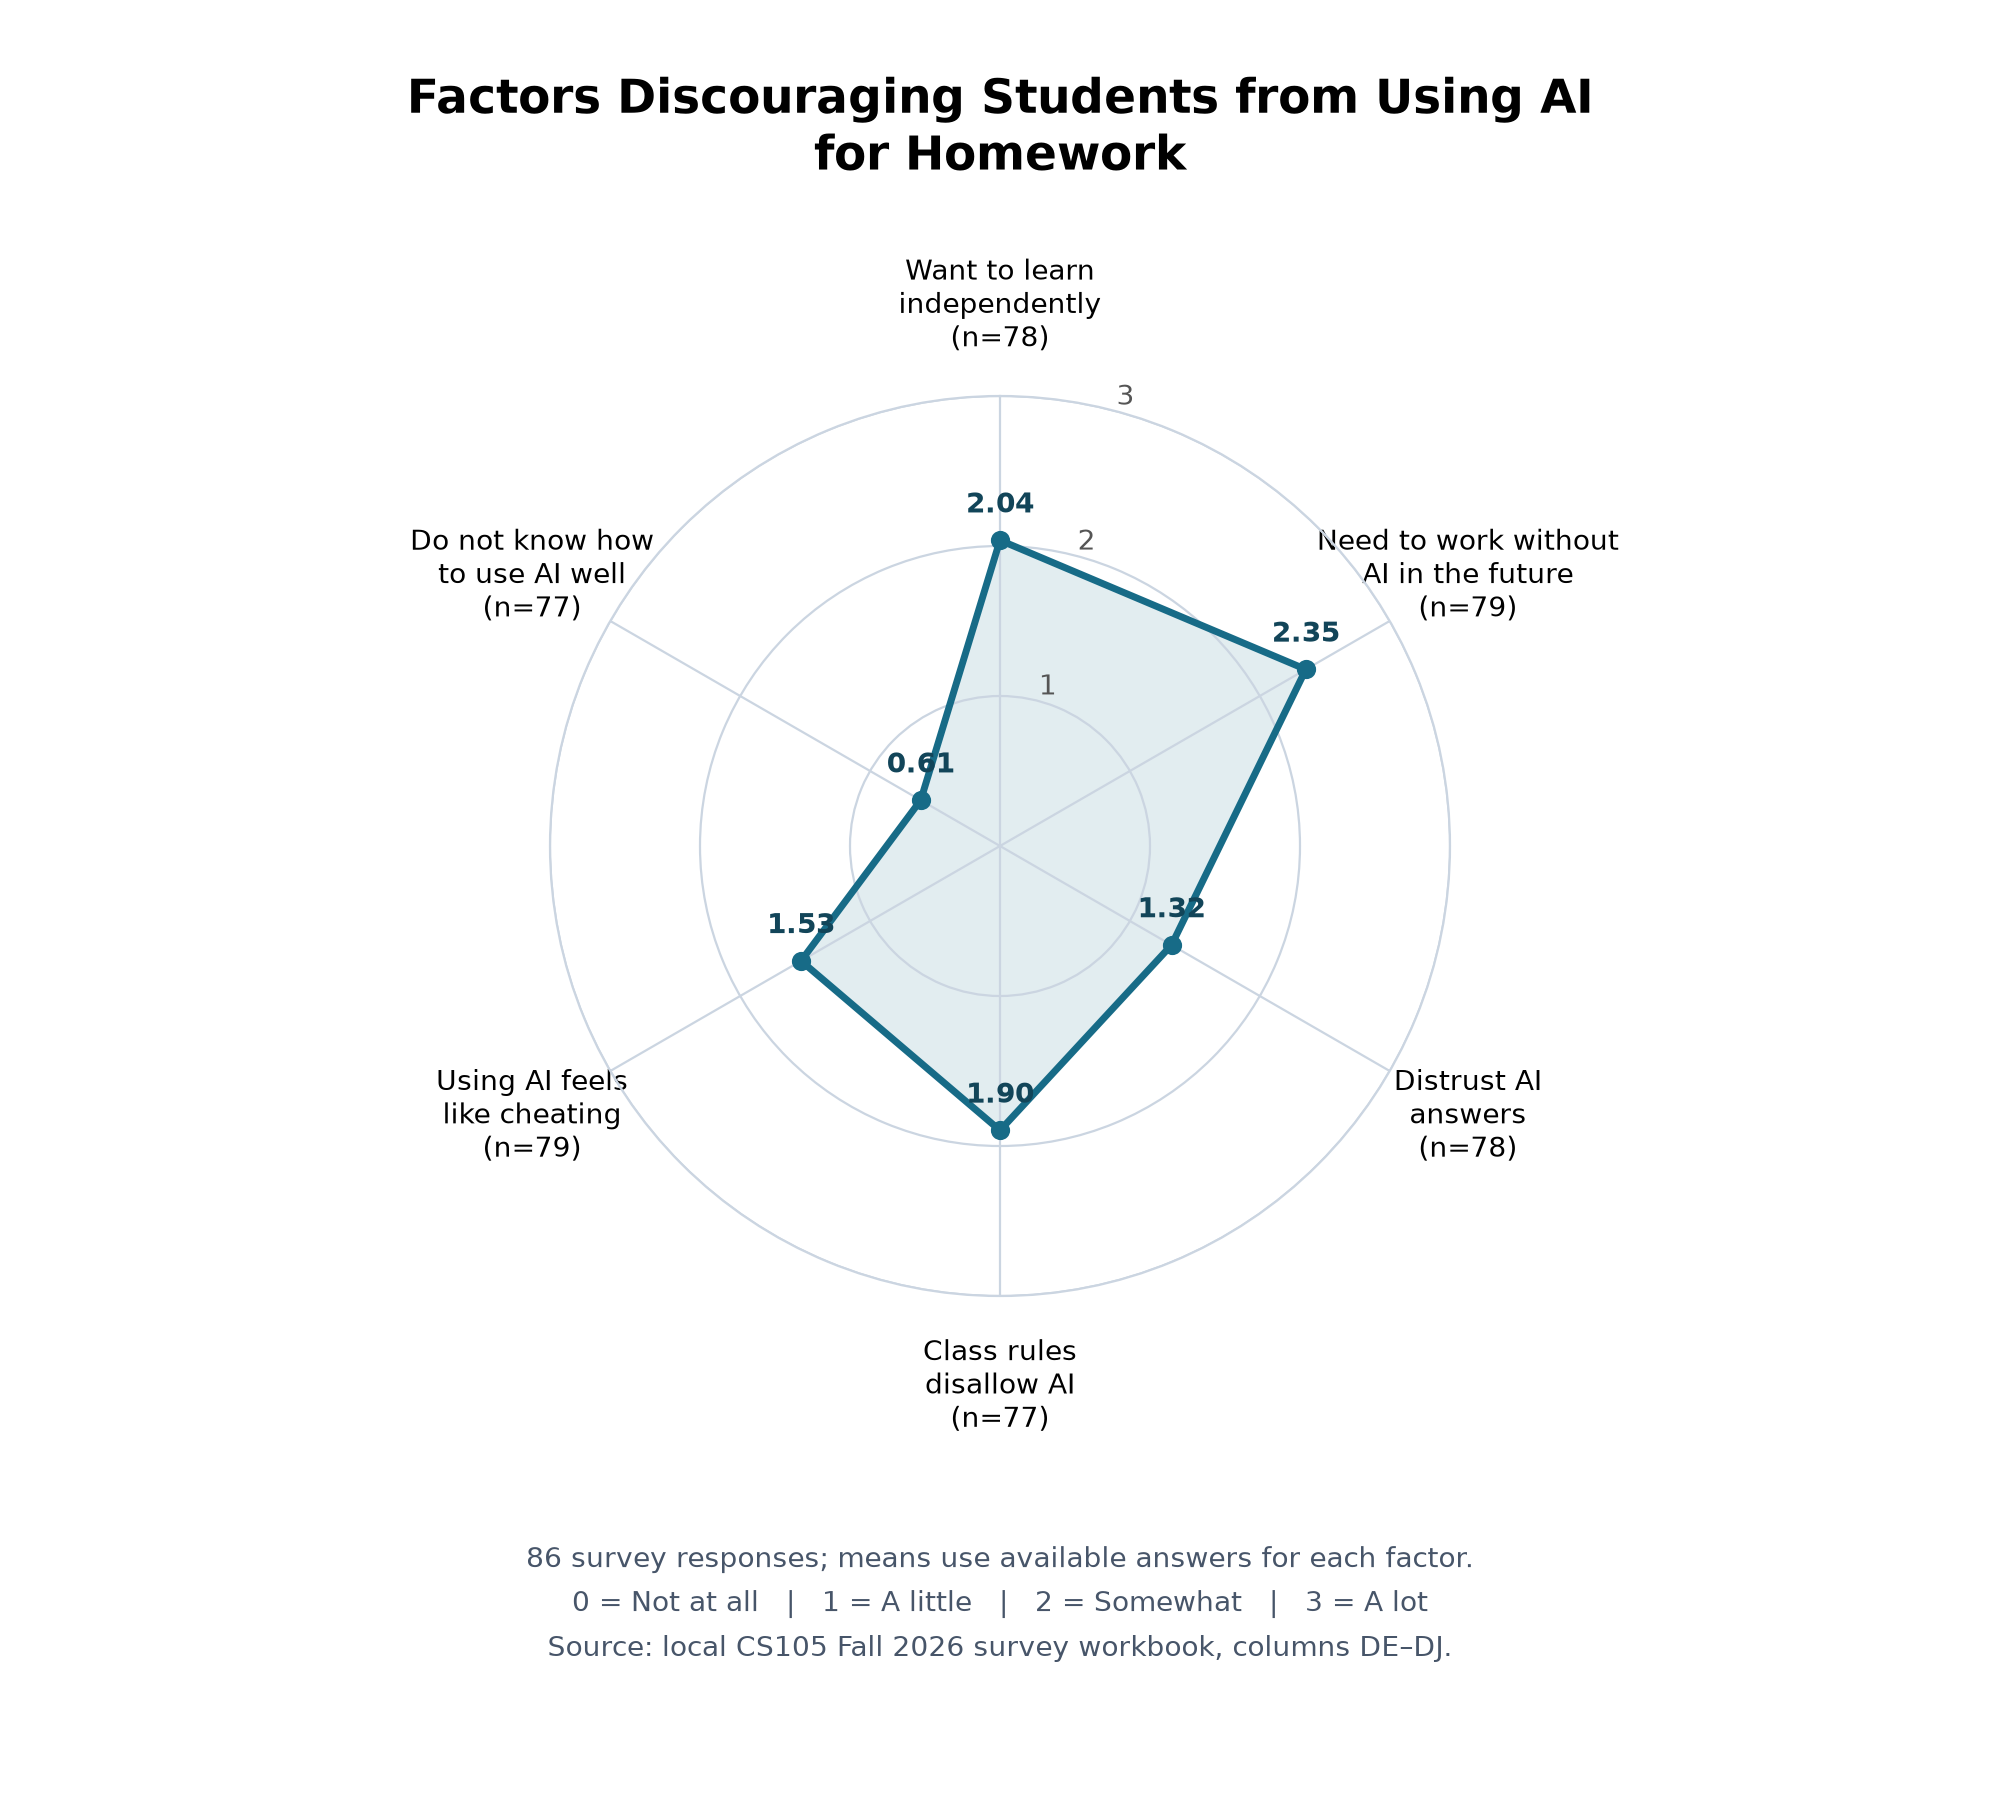

Saved: deterrents_radar.png


In [6]:
import numpy as np
import matplotlib.pyplot as plt

order = list(factors)
means = clean_factors[order].mean().astype(float)
label_text = [
    'Want to learn\nindependently', 'Need to work without\nAI in the future',
    'Distrust AI\nanswers', 'Class rules\ndisallow AI',
    'Using AI feels\nlike cheating', 'Do not know how\nto use AI well',
]
labels = [f'{text}\n(n={int(clean_factors[name].count())})'
          for text, name in zip(label_text, order)]
angles = np.linspace(0, 2 * np.pi, len(order), endpoint=False)
closed_angles = np.r_[angles, angles[0]]
closed_means = np.r_[means.to_numpy(), means.iloc[0]]
fig, ax = plt.subplots(figsize=(10, 9), subplot_kw={'projection': 'polar'})
fig.subplots_adjust(left=0.20, right=0.80, top=0.78, bottom=0.28)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_ylim(0, 3)
ax.set_yticks([1, 2, 3])
ax.set_yticklabels(['1', '2', '3'], color='#555555')
ax.set_rlabel_position(15)
ax.set_xticks(angles)
ax.set_xticklabels(labels, fontsize=10)
ax.tick_params(axis='x', pad=22)
ax.grid(color='#cbd5e1', linewidth=0.8)
ax.spines['polar'].set_color('#cbd5e1')
ax.plot(closed_angles, closed_means, color='#176b87', linewidth=2.5)
ax.fill(closed_angles, closed_means, color='#176b87', alpha=0.12)
ax.scatter(angles, means, color='#176b87', s=35, zorder=3)
for angle, value in zip(angles, means):
    ax.annotate(f'{value:.2f}', xy=(angle, value), xytext=(0, 10),
                textcoords='offset points', ha='center', fontsize=10,
                fontweight='bold', color='#124559')
fig.suptitle('Factors Discouraging Students from Using AI\nfor Homework',
             fontsize=17, fontweight='bold', y=0.96)
fig.text(0.5, 0.08,
         f'{len(data)} survey responses; means use available answers for each factor.\n'
         '0 = Not at all   |   1 = A little   |   2 = Somewhat   |   3 = A lot\n'
         'Source: local CS105 Fall 2026 survey workbook, columns DE–DJ.',
         ha='center', fontsize=10, color='#475569', linespacing=1.6)
radar_path = output_dir / 'deterrents_radar.png'
fig.savefig(radar_path, dpi=200, facecolor='white')
plt.show()
plt.close(fig)
print('Saved:', radar_path.name)


**Interpretation:** Needing to work without AI in the future had the highest mean rating (2.35), followed by wanting to learn independently (2.04). Difficulty using AI had the lowest rating (0.61).


#### Hypothesis: Learning-related deterrents score higher than trust and skill deterrents

**Test and justification:** The scores are paired because both come from the same respondent. For each response with complete answers to DE, DF, DG and DJ, calculate:

- **Learning score:** the average of wanting to learn independently and needing to work without AI later.
- **Trust/skill score:** the average of distrusting AI answers and not knowing how to use AI well.
- **Difference:** learning score minus trust/skill score.

These study-specific scores test the composite hypothesis, not every individual factor comparison.

The primary test is a two-sided paired Wilcoxon signed-rank test at alpha = 0.05. Its null assumes a difference distribution symmetric about zero; a location-shift interpretation requires approximate symmetry. Ties are handled with an asymptotic correction, zero differences are excluded from ranking, and a continuity correction is applied.

An exact two-sided sign test checks whether positive and negative differences are equally likely among nonzero pairs. It does not require symmetric difference magnitudes. Both tests assume independent responses. Because the data were inspected before test selection, the analysis is exploratory.


In [7]:
from scipy import stats
import json

required = ['learn_myself', 'future_independence', 'distrust_answers', 'lack_of_ai_skills']
paired = clean_factors[required].dropna().astype(float).copy()
paired['learning_score'] = paired[['learn_myself', 'future_independence']].mean(axis=1)
paired['trust_skill_score'] = paired[['distrust_answers', 'lack_of_ai_skills']].mean(axis=1)
paired['difference'] = paired['learning_score'] - paired['trust_skill_score']
difference = paired['difference'].to_numpy()
n_positive = int((difference > 0).sum())
n_negative = int((difference < 0).sum())
n_zero = int((difference == 0).sum())
n_nonzero = n_positive + n_negative
if n_nonzero == 0:
    raise ValueError('All paired differences are zero; no signed-rank or sign test is informative.')
wilcoxon_result = stats.wilcoxon(
    difference, alternative='two-sided', zero_method='wilcox',
    method='asymptotic', correction=True,
)
sign_result = stats.binomtest(n_positive, n_nonzero, p=0.5, alternative='two-sided')
nonzero = difference[difference != 0]
ranks = stats.rankdata(np.abs(nonzero))
w_plus = float(ranks[nonzero > 0].sum())
w_minus = float(ranks[nonzero < 0].sum())
rank_biserial = (w_plus - w_minus) / (w_plus + w_minus)
test_results = {
    'alpha': 0.05, 'alternative': 'two-sided',
    'complete_pairs': len(paired), 'excluded_incomplete_responses': len(data) - len(paired),
    'positive_differences': n_positive, 'negative_differences': n_negative,
    'zero_differences': n_zero, 'nonzero_pairs': n_nonzero,
    'learning_score_mean': float(paired['learning_score'].mean()),
    'trust_skill_score_mean': float(paired['trust_skill_score'].mean()),
    'mean_paired_difference': float(np.mean(difference)),
    'median_paired_difference': float(np.median(difference)),
    'difference_q1': float(np.quantile(difference, 0.25)),
    'difference_q3': float(np.quantile(difference, 0.75)),
    'wilcoxon_statistic': float(wilcoxon_result.statistic),
    'wilcoxon_p_value': float(wilcoxon_result.pvalue),
    'wilcoxon_method': 'tie-corrected asymptotic; continuity correction; zero_method=wilcox',
    'matched_pairs_rank_biserial': rank_biserial,
    'exact_sign_test_p_value': float(sign_result.pvalue),
}
print(json.dumps(test_results, indent=2))
print('\nObserved paired-difference distribution:')
print(paired['difference'].value_counts().sort_index().to_string())
paired.to_csv(output_dir / 'deterrents_paired_scores.csv')
(output_dir / 'deterrents_test_results.json').write_text(json.dumps(test_results, indent=2) + '\n')


{
  "alpha": 0.05,
  "alternative": "two-sided",
  "complete_pairs": 76,
  "excluded_incomplete_responses": 10,
  "positive_differences": 55,
  "negative_differences": 2,
  "zero_differences": 19,
  "nonzero_pairs": 57,
  "learning_score_mean": 2.1710526315789473,
  "trust_skill_score_mean": 0.9802631578947368,
  "mean_paired_difference": 1.1907894736842106,
  "median_paired_difference": 1.5,
  "difference_q1": 0.0,
  "difference_q3": 2.0,
  "wilcoxon_statistic": 27.5,
  "wilcoxon_p_value": 1.7571882136893602e-10,
  "wilcoxon_method": "tie-corrected asymptotic; continuity correction; zero_method=wilcox",
  "matched_pairs_rank_biserial": 0.9667271627344223,
  "exact_sign_test_p_value": 2.295386103412511e-14
}

Observed paired-difference distribution:
difference
-1.5     1
-0.5     1
 0.0    19
 0.5     4
 1.0    11
 1.5    15
 2.0    14
 2.5     8
 3.0     3


In [8]:
conclusion = (
    f'Among {len(paired)} complete pairs, the learning score averaged '
    f'{paired["learning_score"].mean():.2f} and the trust/skill score averaged '
    f'{paired["trust_skill_score"].mean():.2f}. The mean paired difference was '
    f'{np.mean(difference):.2f}. Two-sided p-values: Wilcoxon '
    f'{wilcoxon_result.pvalue:.3g}; exact sign test {sign_result.pvalue:.3g}.'
)
(output_dir / 'deterrents_interpretation.txt').write_text(conclusion + '\n');


**Result and conclusion:** Among 76 complete pairs, the learning score averaged 2.17 and the trust/skill score averaged 0.98, a mean paired difference of 1.19 points. The two-sided Wilcoxon test gave W = 27.5, p = 1.76e-10. The exact sign test gave p = 2.3e-14. The observed differences support the predicted direction in this sample.

### Limitations

These are self-reported ratings from a convenience sample. The paired test excludes 10 responses with missing required answers. The composite scores use equally spaced numeric codes for ordinal answers, and the analysis is exploratory.


## Group Contributions

| Member | Contribution |
|---|---|
| slian088 | Selected and cleaned six survey items, summarized ratings, created the radar chart, and ran paired hypothesis tests. |

## Reproducibility
To reproduce the analysis, run all cells in order using Python with pandas, openpyxl, NumPy, Matplotlib, and SciPy. The chart uses available answers for each factor; the tests use complete answers to the four required questions.
